In [3]:
import pandas as pd
import json 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
RESULT_DIR = "/data/Kushal/UniversalRetrieval_data/"

# Multiple Dataset

In [4]:
representative_order = [
    #Popular Representation
    'pipe_serialized',
    'token_serialized',
    'space_serialized',
    # Data Representation
    'csv',
    'tsv',
    'html',
    'markdown',
    'latex',
    'dict',
    'json',
    'xml',
    # Structural Transformations 
    'shuffled_rows',
    'shuffled_cols',
    'transpose',
    #Schema Definition Types
    'mschema',
    'macschema',
    'ddl',
    #Centroid
    "centroid_popular",
    "centroid_data",
    "centroid_schema",
    "centroid_structural",
     "centroid_all",
]
category = {"Popular Representation": ['pipe_serialized',    'token_serialized', 'space_serialized',"centroid_popular"],
    "Data Representation" : [
            'csv',
            'tsv',
            'html',
            'markdown',
            'latex',
            'dict',
            'json',
            'xml',
            'centroid_data'],
    "Structural Transformations": ['shuffled_rows',
        'shuffled_cols',
        'transpose',
        'centroid_structural'],
    "Schema Definition Types" :['mschema',
    'macschema',
    'ddl',
    'centroid_schema'],
    "All" :['centroid_all'],
}
category_wo_centroid = {"Popular Representation": ['pipe_serialized',    'token_serialized', 'space_serialized'],
    "Data Representation" : [
            'csv',
            'tsv',
            'html',
            'markdown',
            'latex',
            'dict',
            'json',
            'xml',
            ],
    "Structural Transformations": ['shuffled_rows',
        'shuffled_cols',
        'transpose'],
    "Schema Definition Types" :['mschema',
    'macschema',
    'ddl'],
}

In [5]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

topk_list = [1, 5, 10]
df_list = []

for dataset in ["WTQ", "WIKISQL", "NQ"]:
    for model in ["splade","qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]:
        df_model = None
        for representative in representative_order:
            fpath = f'{RESULT_DIR}/retrieval_all/{model}_results_rank/{dataset}/chunked_{representative.replace("centroid", "centroid_centroid") if "centroid_all" not in representative else representative}_gold_rank_per_question.csv'
            if not Path(fpath).exists():
                print(f"[skip] {fpath}")
                continue
            df = pd.read_csv(fpath)
            df = df[["model", "dataset", "question_id", "rank"]].copy()
            rename_dict = {"rank": representative}
            for topk in topk_list:
                df[f"recall@{topk}"] = (df["rank"] <= topk).astype(int)
                df[f"ndcg@{topk}"] = np.where(
                    df["rank"] <= topk,
                    1 / np.log2(df["rank"] + 1),
                    0.0
                )
                rename_dict[f"recall@{topk}"] = f"{representative}_recall@{topk}"
                rename_dict[f"ndcg@{topk}"] = f"{representative}_ndcg@{topk}"
            df_renamed = df.rename(columns=rename_dict)
            if df_model is None:
                df_model = df_renamed
            else:
                df_model = df_model.merge(
                    df_renamed,
                    on=["model", "dataset", "question_id"],
                    how="inner",
                    validate="one_to_one",
                )
        if df_model is not None:
            df_list.append(df_model)

df = pd.concat(df_list, ignore_index=True)

/tmp/ipykernel_2845133/1697098094.py:68: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(


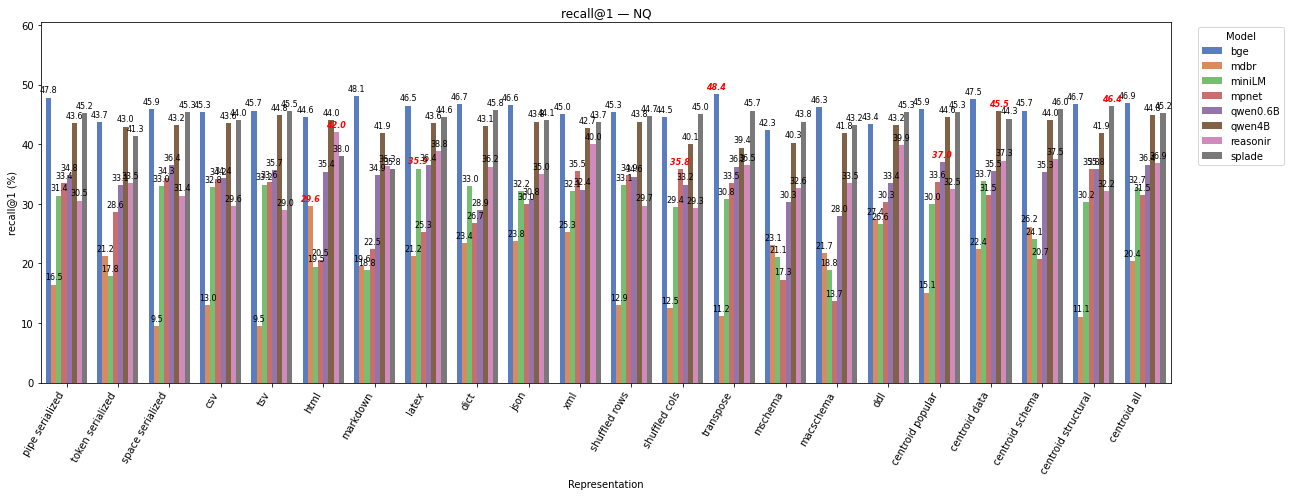

/tmp/ipykernel_2845133/1697098094.py:68: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(


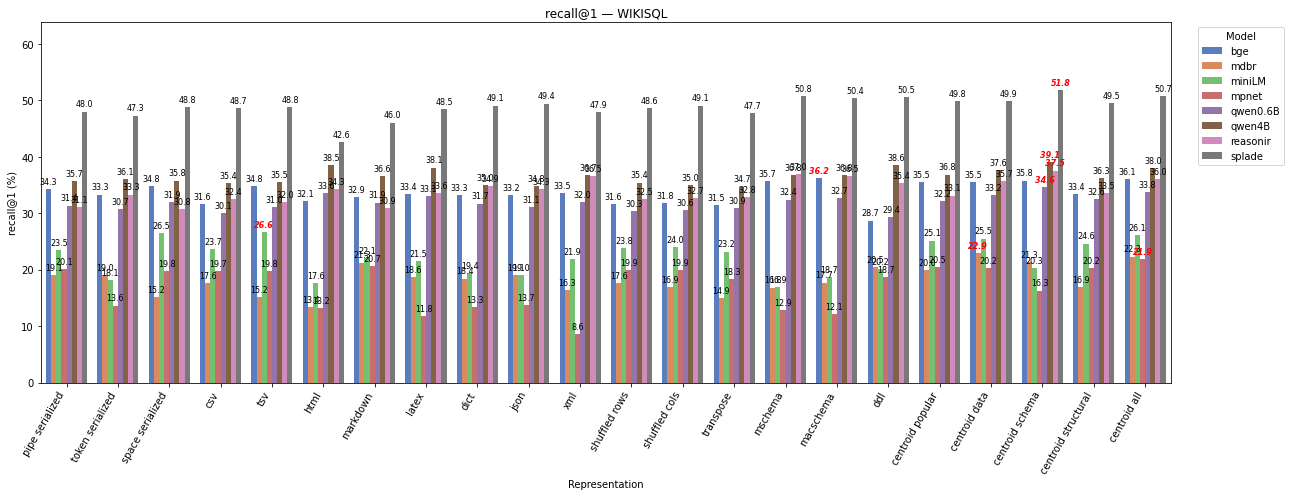

/tmp/ipykernel_2845133/1697098094.py:68: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(


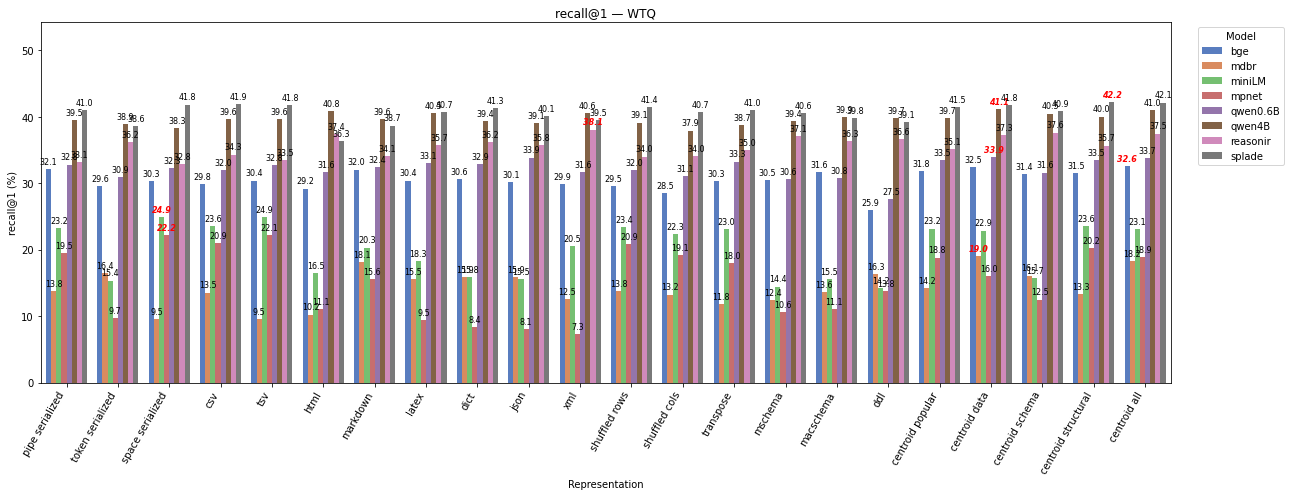

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
topk=1
metric="recall"
methods = [
    "pipe_serialized",
    "token_serialized",
    "space_serialized",
    "csv",
    "tsv",
    "html",
    "markdown",
    "latex",
    "dict",
    "json",
    "xml",
    "shuffled_rows",
    "shuffled_cols",
    "transpose",
    "mschema",
    "macschema",
    "ddl",
    "centroid_popular",
    "centroid_data",
    "centroid_schema",
    "centroid_structural",
    "centroid_all",
]
# Calculate mean metric@1 for each dataset, model, and method
metric_df = pd.DataFrame({
    method: df.groupby(["dataset", "model"])[f"{method}_{metric}@{topk}"].mean()
    for method in methods
})
# Convert to long format
plot_df = (
    metric_df
    .reset_index()
    .melt(
        id_vars=["dataset", "model"],
        var_name="representation",
        value_name=f"{metric}"
    )
)
# Clean representation names
plot_df["representation"] = plot_df["representation"].str.replace(
    "_", " ", regex=False
)
# Plot one graph per dataset
for dataset in plot_df["dataset"].unique():
    data = plot_df[plot_df["dataset"] == dataset]
    plt.figure(figsize=(18, 7))
    ax = sns.barplot(
        data=data,
        x="representation",
        y=f"{metric}",
        hue="model",
        errorbar=None,
        palette="muted"
    )
    ax.set_ylabel(f"{metric}@{topk} (%)")
    ax.set_xlabel("Representation")
    ax.set_title(f"{metric}@{topk} — {dataset}")
    # Leave room for labels above bars
    ymax = min(1, data[f"{metric}"].max() + 0.12)
    ax.set_ylim(0, ymax)
    # Format y-axis as percentages
    ax.set_yticklabels(
        [f"{x * 100:.0f}" for x in ax.get_yticks()]
    )
    # Add values on top of each bar, bolding the top representation
    # per model and italicizing the runner-up
    for container in ax.containers:
        heights = [bar.get_height() for bar in container]
        labels = [
            f"{h * 100:.1f}" if h > 0 else ""
            for h in heights
        ]
        texts = ax.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=8
        )
        ranked_idx = sorted(
            range(len(heights)),
            key=lambda i: heights[i],
            reverse=True
        )
        if len(ranked_idx) >= 1:
            texts[ranked_idx[0]].set_fontstyle("italic")
            texts[ranked_idx[0]].set_fontweight("bold")
            texts[ranked_idx[0]].set_color("red")
        #if len(ranked_idx) >= 2:
        #    texts[ranked_idx[1]].set_fontstyle("italic")
        #    texts[ranked_idx[1]].set_fontweight("bold")
        #    texts[ranked_idx[1]].set_color("blue")
    plt.xticks(rotation=60, ha="right")
    plt.legend(
        title="Model",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    plt.tight_layout()
    plt.show()

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import ttest_rel
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

def pairwise_ttest_heatmap(
    g: pd.DataFrame,
    representative_order: list,
    *,
    score_suffix: str = "_gold_score",
    alpha: float = 0.01,
    correction: str = "fdr_bh",   # "fdr_bh", "bonferroni", etc. or None
    reorder_by: str = "mean",      # currently supports "mean"
    use_adjusted_for_plot: bool = True,
    pvalue_vmax: float = 0.10,     # cap heatmap scale to emphasize significance region
    annotate: bool = False,
    min_pairs: int = 2,
    title_prefix: str = "",
    show: bool = True,
):

    # 1) Validate and build score table
    score_cols = [f"{rep}{score_suffix}" for rep in representative_order]
    missing = [c for c in score_cols if c not in g.columns]
    if missing:
        raise ValueError(f"Missing expected score columns in group: {missing}")

    scores = g[score_cols].copy()
    scores.columns = representative_order

    # 2) Reorder
    if reorder_by != "mean":
        raise ValueError(f"Unsupported reorder_by='{reorder_by}'. Use 'mean'.")
    mean_perf = scores.mean(axis=0, skipna=True).sort_values(ascending=True)
    ordered_reps = mean_perf.index.tolist()
    scores = scores[ordered_reps]

    n = len(ordered_reps)
    pvals = pd.DataFrame(np.nan, index=ordered_reps, columns=ordered_reps)
    tstats = pd.DataFrame(np.nan, index=ordered_reps, columns=ordered_reps)
    mean_diff = pd.DataFrame(np.nan, index=ordered_reps, columns=ordered_reps)

    # For one-triangle correction
    raw_p_list = []
    pair_idx = []

    # 3) Pairwise paired t-tests
    for i in range(n):
        for j in range(n):
            if i == j:
                mean_diff.iat[i, j] = 0.0
                continue

            a = scores.iloc[:, i]
            b = scores.iloc[:, j]
            valid = a.notna() & b.notna()
            av = a[valid]
            bv = b[valid]

            if len(av) < min_pairs:
                continue

            stat, p = ttest_rel(av, bv, nan_policy="omit")
            tstats.iat[i, j] = stat
            pvals.iat[i, j] = p
            mean_diff.iat[i, j] = (av - bv).mean()

            if i > j:  # unique test
                raw_p_list.append(p)
                pair_idx.append((i, j))

    pvals_adj = pvals.copy()
    sig_mask = pvals_adj < alpha

    p_for_sig = pvals_adj if (correction is not None) else pvals
    p_for_plot = pvals_adj if (use_adjusted_for_plot and correction is not None) else pvals

    # 5) Summary and win counts
    summary = pd.DataFrame({
        "mean_score": mean_perf,
        "rank": np.arange(1, len(mean_perf) + 1),
    })

    win_counts = pd.Series(0, index=ordered_reps, dtype=int)
    for i, r in enumerate(ordered_reps):
        for j, c in enumerate(ordered_reps):
            if i == j:
                continue
            p = p_for_sig.iat[i, j]
            md = mean_diff.iat[i, j]
            if pd.notna(p) and pd.notna(md) and (p < alpha) and (md < 0):
                win_counts[r] += 1

    # 6) Plots
    fig_pvals = None
    fig_effect = None

    if show:
        # lower triangle only
        mask = np.triu(np.ones_like(p_for_plot, dtype=bool), k=0)

        fig, axes = plt.subplots(figsize=(16, 6),ncols=2)
        ax1,ax2 = axes[0],axes[1]
        # Effect size/direction heatmap
        mask2 = np.triu(np.ones_like(mean_diff, dtype=bool), k=0)
        sns.heatmap(
            mean_diff,
            mask=mask2,
            cmap="coolwarm",
            center=0,
            square=True,
            linewidths=0.5,
            vmin=-30,
            vmax=30,
            cbar_kws={"label": "Mean difference (row - col)"},
            annot=annotate,
            fmt=".3f",
            ax=ax1,
        )
        ax1.set_title(f"{title_prefix} Pairwise Mean Differences\n(lower triangle, reordered by mean performance)".strip())
        ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right")
        ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0)
        sns.heatmap(
            p_for_plot,
            mask=mask,
            cmap="viridis_r",
            vmin=0,
            vmax=0.1,
            square=True,
            linewidths=0.5,
            cbar_kws={"label": "Adjusted p-value" if (use_adjusted_for_plot and correction is not None) else "Raw p-value"},
            annot=annotate,
            fmt=".3f",
            ax=ax2,
        )
        suffix = f" ({correction})" if (use_adjusted_for_plot and correction is not None) else " (raw)"
        ax2.set_title(f"{title_prefix} Pairwise Paired t-test p-values{suffix}\n(lower triangle, reordered by mean performance)".strip())
        ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha="right")
        ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0)


        fig.tight_layout()
        plt.show()

    return {
        "summary": summary,
        "pvals_raw": pvals,
        "pvals_adj": pvals_adj,
        "tstats": tstats,
        "mean_diff": mean_diff,
        "sig_mask": sig_mask,
        "win_counts": win_counts.sort_values(ascending=False),
        "ordered_reps": ordered_reps,
        "fig_pvals": fig_pvals,
        "fig_effect": fig_effect,
    }
def pairwise_wilcoxon_heatmap(
    g: pd.DataFrame,
    representative_order: list,
    *,
    score_suffix: str = "_gold_score",
    alpha: float = 0.01,
    correction: str = "fdr_bh",   # "fdr_bh", "bonferroni", etc. or None
    reorder_by: str = "mean",     # currently supports "mean"
    use_adjusted_for_plot: bool = True,
    pvalue_vmax: float = 0.10,    # cap heatmap scale to emphasize significance region
    annotate: bool = False,
    min_pairs: int = 2,
    title_prefix: str = "",
    show: bool = True,
    zero_method: str = "wilcox",  # "wilcox", "pratt", or "zsplit"
    alternative: str = "two-sided",
):
    # 1) Validate and build score table
    score_cols = [f"{rep}{score_suffix}" for rep in representative_order]
    missing = [c for c in score_cols if c not in g.columns]
    if missing:
        raise ValueError(f"Missing expected score columns in group: {missing}")

    scores = g[score_cols].copy()
    scores.columns = representative_order

    # 2) Reorder
    if reorder_by != "mean":
        raise ValueError(f"Unsupported reorder_by='{reorder_by}'. Use 'mean'.")
    mean_perf = scores.mean(axis=0, skipna=True).sort_values(ascending=True)
    ordered_reps = mean_perf.index.tolist()
    scores = scores[ordered_reps]

    n = len(ordered_reps)
    pvals = pd.DataFrame(np.nan, index=ordered_reps, columns=ordered_reps)
    wstats = pd.DataFrame(np.nan, index=ordered_reps, columns=ordered_reps)
    mean_diff = pd.DataFrame(np.nan, index=ordered_reps, columns=ordered_reps)

    # For one-triangle correction
    raw_p_list = []
    pair_idx = []

    # 3) Pairwise paired Wilcoxon signed-rank tests
    for i in range(n):
        for j in range(n):
            if i == j:
                mean_diff.iat[i, j] = 0.0
                continue

            a = scores.iloc[:, i]
            b = scores.iloc[:, j]
            valid = a.notna() & b.notna()
            av = a[valid]
            bv = b[valid]

            if len(av) < min_pairs:
                continue

            diffs = av - bv
            mean_diff.iat[i, j] = diffs.mean()

            # Wilcoxon can fail if all paired differences are zero
            if np.allclose(diffs.to_numpy(), 0):
                wstats.iat[i, j] = 0.0
                pvals.iat[i, j] = 1.0
                if i > j:
                    raw_p_list.append(1.0)
                    pair_idx.append((i, j))
                continue

            try:
                stat, p = wilcoxon(
                    av,
                    bv,
                    zero_method=zero_method,
                    alternative=alternative,
                    correction=False,
                    mode="auto",
                )
                wstats.iat[i, j] = stat
                pvals.iat[i, j] = p

                if i > j:  # unique test
                    raw_p_list.append(p)
                    pair_idx.append((i, j))

            except ValueError:
                # Fallback for edge cases such as insufficient non-zero differences
                continue

    # 4) Multiple testing correction on lower triangle, then mirror
    pvals_adj = pvals.copy()

    if correction is not None and len(raw_p_list) > 0:
        _, adj_pvals, _, _ = multipletests(raw_p_list, alpha=alpha, method=correction)

        for (i, j), p_adj in zip(pair_idx, adj_pvals):
            pvals_adj.iat[i, j] = p_adj
            pvals_adj.iat[j, i] = p_adj

    p_for_sig = pvals_adj if (correction is not None) else pvals
    p_for_plot = pvals_adj if (use_adjusted_for_plot and correction is not None) else pvals
    sig_mask = p_for_sig < alpha

    # 5) Summary and win counts
    summary = pd.DataFrame({
        "mean_score": mean_perf,
        "rank": np.arange(1, len(mean_perf) + 1),
    })

    win_counts = pd.Series(0, index=ordered_reps, dtype=int)
    for i, r in enumerate(ordered_reps):
        for j, c in enumerate(ordered_reps):
            if i == j:
                continue
            p = p_for_sig.iat[i, j]
            md = mean_diff.iat[i, j]
            if pd.notna(p) and pd.notna(md) and (p < alpha) and (md < 0):
                win_counts[r] += 1

    # 6) Plots
    fig_pvals = None
    fig_effect = None

    if show:
        mask = np.triu(np.ones_like(p_for_plot, dtype=bool), k=0)
        mask2 = np.triu(np.ones_like(mean_diff, dtype=bool), k=0)

        fig, axes = plt.subplots(figsize=(16, 6), ncols=2)
        ax1, ax2 = axes[0], axes[1]

        sns.heatmap(
            mean_diff,
            mask=mask2,
            cmap="coolwarm",
            center=0,
            square=True,
            linewidths=0.5,
            vmin=-30,
            vmax=30,
            cbar_kws={"label": "Mean Paired Rank Difference (row − col)"},
            annot=annotate,
            fmt=".3f",
            ax=ax1,
        )
        ax1.set_title(
            f"Average paired rank difference".strip()
        )
        ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right")
        ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0)

        sns.heatmap(
            p_for_plot,
            mask=mask,
            cmap="viridis_r",
            vmin=0,
            vmax=pvalue_vmax,
            square=True,
            linewidths=0.5,
            cbar_kws={
                "label": "Adjusted p-value"
                if (use_adjusted_for_plot and correction is not None)
                else "Raw p-value"
            },
            annot=annotate,
            fmt=".3f",
            ax=ax2,
        )
        ax2.set_title(
            f"FDR-adjusted Wilcoxon p-values".strip()
        )
        ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha="right")
        ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0)

        fig.tight_layout()
        plt.show()

    return {
        "summary": summary,
        "pvals_raw": pvals,
        "pvals_adj": pvals_adj,
        "wstats": wstats,
        "mean_diff": mean_diff,
        "sig_mask": sig_mask,
        "win_counts": win_counts.sort_values(ascending=False),
        "ordered_reps": ordered_reps,
        "fig_pvals": fig_pvals,
        "fig_effect": fig_effect,
    }

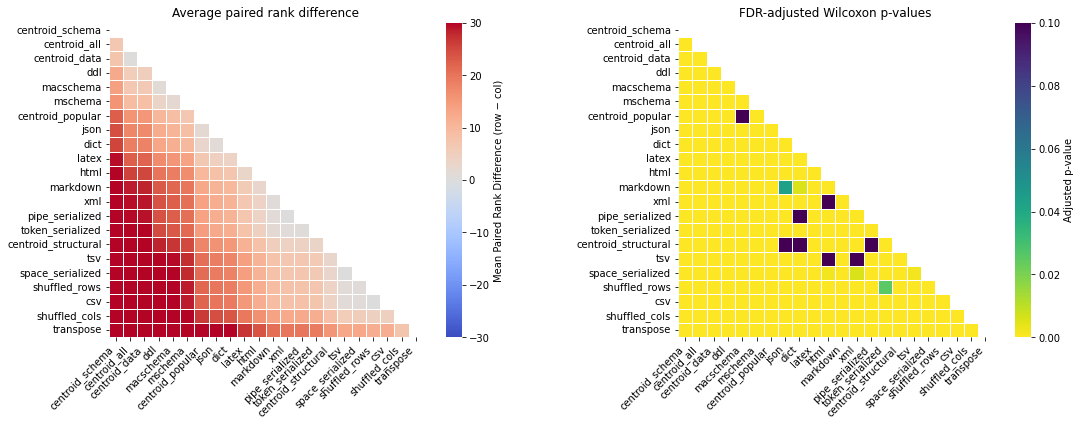


model=ALL
                 mean_score  rank
centroid_schema   71.564935     1
centroid_all      78.485073     2
centroid_data     78.948756     3
ddl               84.054849     4
macschema         85.402799     5
Significant wins:
centroid_schema     21
centroid_all        20
centroid_data       19
ddl                 18
macschema           16
mschema             16
centroid_popular    15
json                13
latex               12
dict                11
dtype: int64


In [8]:
g = df
title = f"model=ALL"
out = pairwise_wilcoxon_heatmap(
    g,
    representative_order,
    score_suffix="",
    correction="holm",
    alpha=0.05,
    use_adjusted_for_plot=True,
    pvalue_vmax=0.10,
    title_prefix=title,
    show=True,    # set False if you only want returned matrices
)

# Example: print top performers in this group
print("\n" + "="*80)
print(title)
print(out["summary"].head(5))
print("Significant wins:")
print(out["win_counts"].head(10))

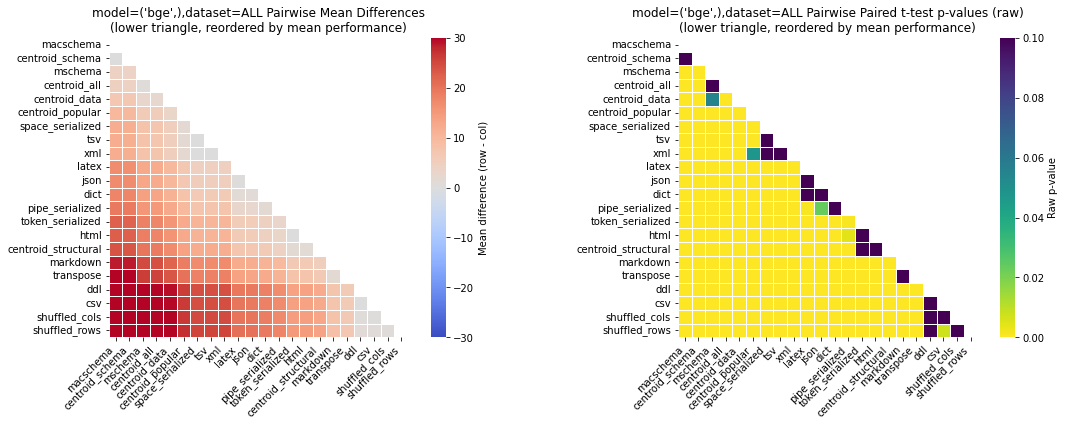


model=('bge',),dataset=ALL
                 mean_score  rank
macschema         52.576269     1
centroid_schema   52.799088     2
mschema           56.600456     3
centroid_all      57.209799     4
centroid_data     59.382912     5
Significant wins:
macschema           20
centroid_schema     20
centroid_all        18
mschema             17
centroid_data       17
centroid_popular    16
space_serialized    13
tsv                 13
xml                 13
latex               10
dtype: int64


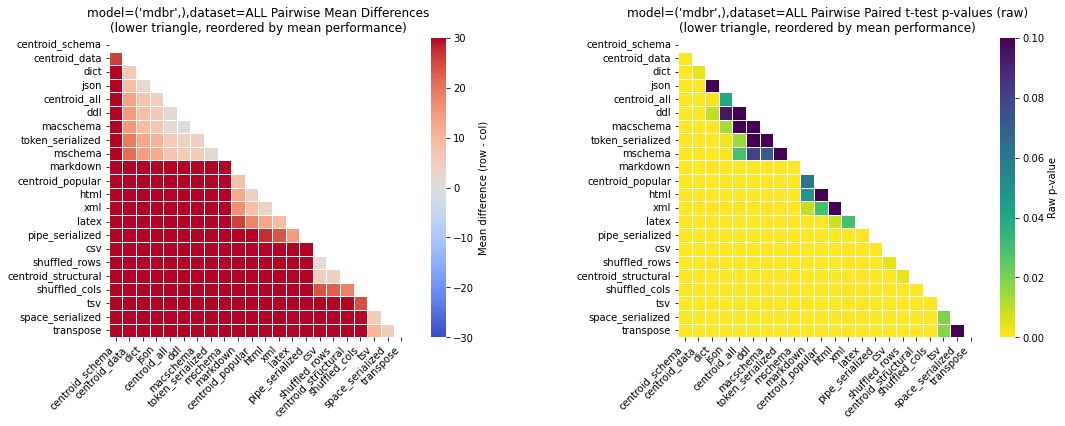


model=('mdbr',),dataset=ALL
                 mean_score  rank
centroid_schema  138.791580     1
centroid_data    164.665891     2
dict             170.813011     3
json             173.094754     4
centroid_all     177.917649     5
Significant wins:
centroid_schema     21
centroid_data       20
dict                18
json                17
centroid_all        15
ddl                 13
macschema           13
token_serialized    13
mschema             13
markdown            11
dtype: int64


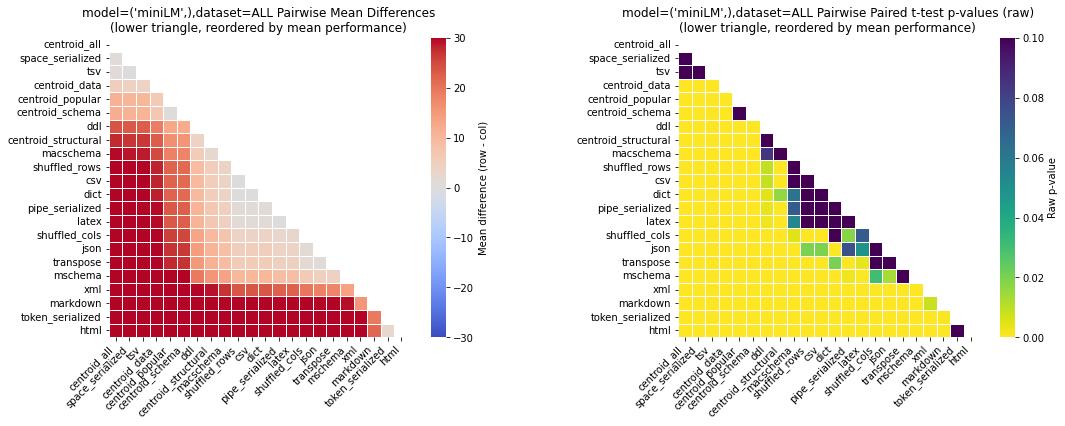


model=('miniLM',),dataset=ALL
                  mean_score  rank
centroid_all       98.757936     1
space_serialized   99.651825     2
tsv                99.826316     3
centroid_data     103.682190     4
centroid_popular  109.981420     5
Significant wins:
centroid_all           19
tsv                    19
space_serialized       19
centroid_data          18
centroid_popular       16
centroid_schema        16
ddl                    13
centroid_structural    13
macschema               8
shuffled_rows           8
dtype: int64


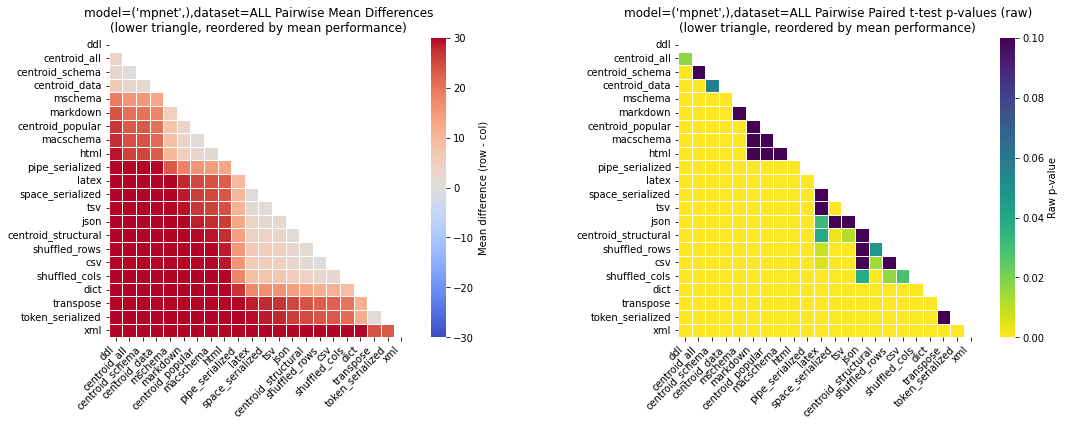


model=('mpnet',),dataset=ALL
                 mean_score  rank
ddl               95.272809     1
centroid_all      98.469778     2
centroid_schema   98.727048     3
centroid_data    101.179719     4
mschema          114.107964     5
Significant wins:
ddl                 21
centroid_all        19
centroid_schema     18
centroid_data       18
mschema             16
markdown            13
centroid_popular    13
macschema           13
html                13
pipe_serialized     12
dtype: int64


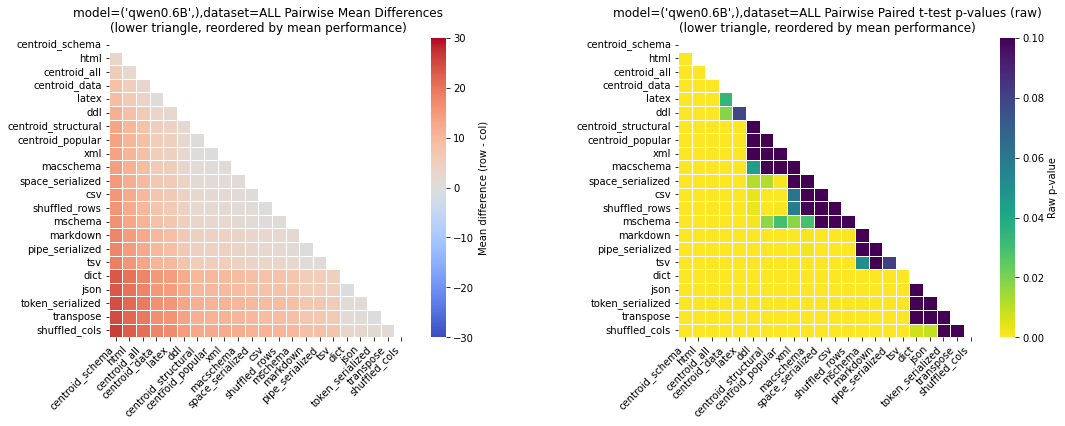


model=('qwen0.6B',),dataset=ALL
                 mean_score  rank
centroid_schema   51.467497     1
html              54.549658     2
centroid_all      56.787493     3
centroid_data     59.598318     4
latex             60.427438     5
Significant wins:
centroid_schema        21
html                   20
centroid_all           19
centroid_data          18
latex                  16
ddl                    13
centroid_structural    12
centroid_popular       12
xml                     9
macschema               9
dtype: int64


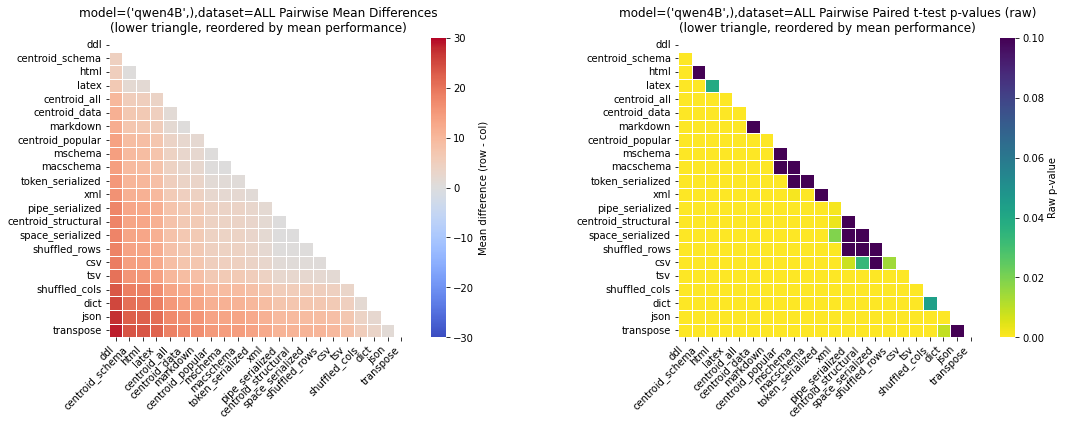


model=('qwen4B',),dataset=ALL
                 mean_score  rank
ddl               37.229234     1
centroid_schema   41.912992     2
html              42.196446     3
latex             43.719445     4
centroid_all      47.300228     5
Significant wins:
ddl                 21
centroid_schema     19
html                19
latex               18
centroid_all        17
centroid_data       15
markdown            15
centroid_popular    12
mschema             11
macschema           11
dtype: int64


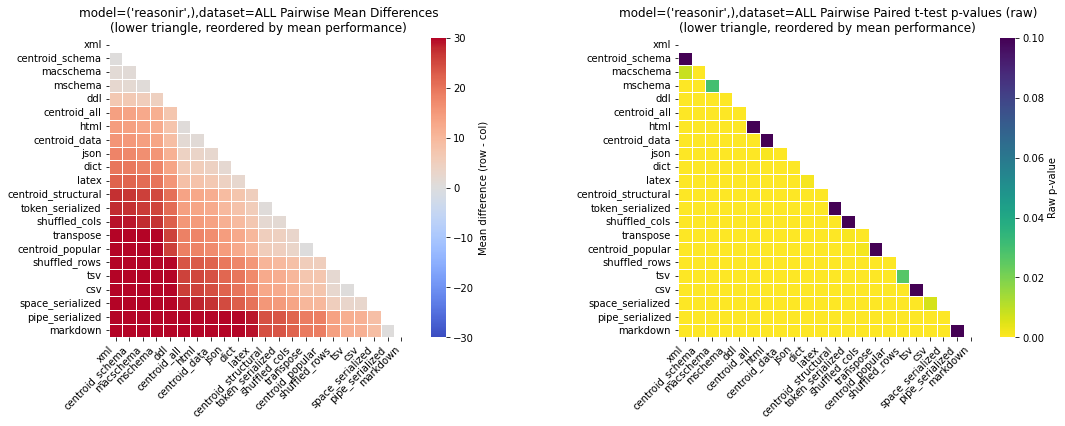


model=('reasonir',),dataset=ALL
                 mean_score  rank
xml               51.683045     1
centroid_schema   52.035782     2
macschema         53.077884     3
mschema           53.902680     4
ddl               58.370557     5
Significant wins:
xml                20
centroid_schema    20
macschema          19
mschema            18
ddl                17
centroid_all       15
html               14
centroid_data      14
json               13
dict               12
dtype: int64


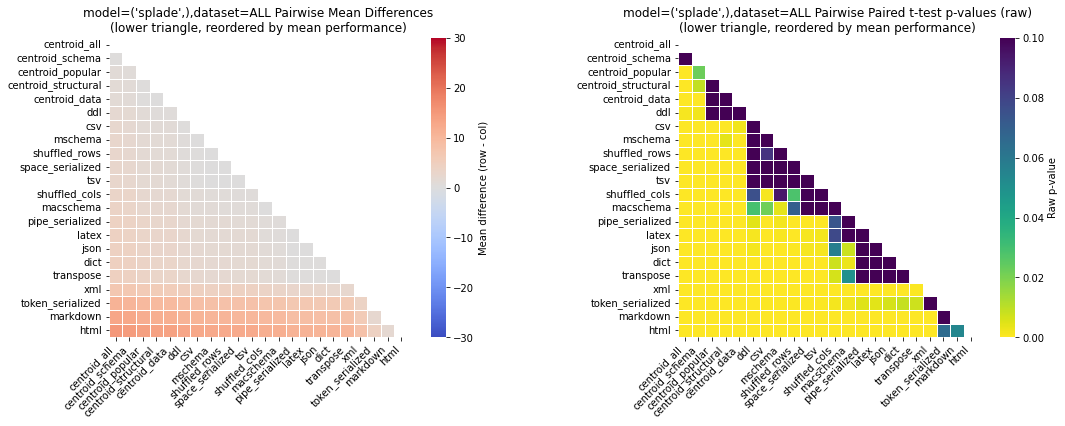


model=('splade',),dataset=ALL
                     mean_score  rank
centroid_all          25.889422     1
centroid_schema       26.219730     2
centroid_popular      26.954619     3
centroid_structural   27.244108     4
centroid_data         27.291437     5
Significant wins:
centroid_all           20
centroid_schema        20
centroid_popular       16
centroid_structural    16
centroid_data          16
csv                    11
ddl                    10
mschema                10
shuffled_rows          10
space_serialized        9
dtype: int64


In [9]:
results_by_group = {}
d="ALL"
for (m), g in df.groupby(["model"], dropna=False):
    title = f"model={m},dataset={d}"
    out = pairwise_ttest_heatmap(
        g,
        representative_order,
        score_suffix="",# "" means use rank, "_hit@1" means use hit@1
        correction=None,
        alpha=0.05,
        use_adjusted_for_plot=False,
        pvalue_vmax=0.10,
        title_prefix=title,
        show=True,    # set False if you only want returned matrices
    )
    results_by_group[(m, d)] = out

    # Example: print top performers in this group
    print("\n" + "="*80)
    print(title)
    print(out["summary"].head(5))
    print("Significant wins:")
    print(out["win_counts"].head(10))



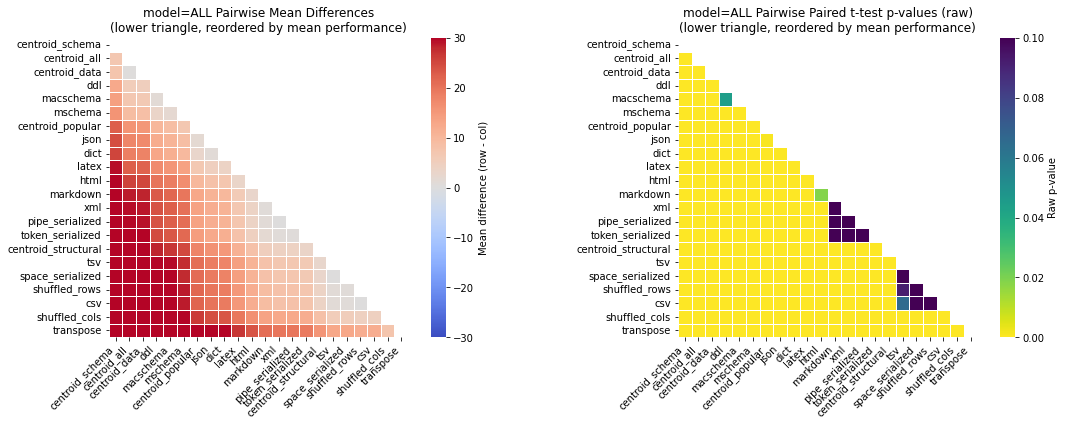


model=ALL
                 mean_score  rank
centroid_schema   71.564935     1
centroid_all      78.485073     2
centroid_data     78.948756     3
ddl               84.054849     4
macschema         85.402799     5
Significant wins:
centroid_schema     21
centroid_all        20
centroid_data       19
ddl                 18
macschema           17
mschema             16
centroid_popular    15
json                14
dict                13
latex               12
dtype: int64


In [10]:
g = df
title = f"model=ALL"
out = pairwise_ttest_heatmap(
    g,
    representative_order,
    score_suffix="",
    correction=None,
    alpha=0.05,
    use_adjusted_for_plot=True,
    pvalue_vmax=0.10,
    title_prefix=title,
    show=True,    # set False if you only want returned matrices
)

# Example: print top performers in this group
print("\n" + "="*80)
print(title)
print(out["summary"].head(5))
print("Significant wins:")
print(out["win_counts"].head(10))
